# Linear Algebra for Data Science 2026 — Lab 2, Core A
# Power iteration and inverse iteration

### <div align="right"> &copy; Rostyslav Hryniv, 2026, after V. Kuchynskyi & R. Hryniv, 2023 </div>

## Completed by:
*   Yulian Melnychuk
*   Second team member — *(write the name here, or delete this line if you worked alone)*

**Marked at the defence:** Core A is worth 2 points; the starred extensions at the end are one of three routes to the extension point (see the brief).

## Why this core

PageRank (Core B), the smoothing step in a graph neural network, and — later in the course — the leading principal component all need **one** eigenpair of a very large matrix that you can only *multiply by*. Power iteration is the algorithm that needs nothing more than $\mathbf{x}\mapsto A\mathbf{x}$. This core makes you implement it, **predict its speed before you run it**, find out where it breaks, and then use *inverse iteration with a shift* to reach the other eigenvalues.

**Uses:** Lecture 3.1 ($A^n = PD^nP^{-1}$, the Jordan asymptotics $n^k|\lambda|^n$, the role of $\kappa(P)$) and Lecture 3.2 (power iteration, inverse iteration). LU factorisation is a Module 0 prerequisite.

**Rules for this notebook**
* Inside `power_method` and `inverse_iteration` do **not** call `np.linalg.eig`, `np.linalg.eigvals`, `scipy.linalg.eig` or anything that calls them. You may use them elsewhere to *check* your results.
* Never call `np.linalg.inv` anywhere in this notebook. If you need $P^{-1}$ applied to something, solve a system.
* Every number you report must be reproduced by `Restart & Run All`.

In [1]:
import sys, numpy as np, scipy, scipy.linalg as sla, matplotlib
import matplotlib.pyplot as plt
print('python', sys.version.split()[0], '| numpy', np.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)
rng = np.random.default_rng(2026)   # do not change the seed: the defence uses your numbers

python 3.13.16 | numpy 2.5.3 | scipy 1.18.1 | matplotlib 3.11.2


### Two provided helpers

`sin_angle(u, v)` measures how far apart two *directions* are. It ignores length and sign (and, for complex vectors, any unimodular factor), so it is the right error measure for an eigenvector.

`similar_matrix(eigvals, P)` returns $A = P\,\mathrm{diag}(\text{eigvals})\,P^{-1}$ **without** forming $P^{-1}$: from $AP = PD$ we get $P^\top A^\top = (PD)^\top$, which is one linear solve.

In [2]:
def sin_angle(u, v):
    # sine of the angle between span{u} and span{v}; accurate for small angles
    u = u / np.linalg.norm(u)
    v = v / np.linalg.norm(v)
    return np.linalg.norm(u - v * np.vdot(v, u))

def similar_matrix(eigvals, P):
    # A = P diag(eigvals) P^{-1}, computed by one solve instead of an inverse
    PD = P * np.asarray(eigvals)[None, :]          # scales column j of P by eigvals[j]
    return np.linalg.solve(P.T, PD.T).T

def random_orthogonal(n):
    Q, R = np.linalg.qr(rng.standard_normal((n, n)))
    return Q * np.sign(np.diag(R))                  # sign fix: a uniformly random orthogonal Q

---
## 1. Power iteration

### 1.1 The idea, recalled
Let $A$ be a diagonalisable $k\times k$ matrix with eigenvalues ordered so that $|\lambda_1| > |\lambda_2| \ge \dots \ge |\lambda_k|$ (so $\lambda_1$ is real and simple when $A$ is real) and eigenvectors $\mathbf{v}_1,\dots,\mathbf{v}_k$. Write $\mathbf{x}_0 = c_1\mathbf{v}_1 + \dots + c_k\mathbf{v}_k$ with $c_1 \ne 0$. Then
$$
A^n\mathbf{x}_0 = \lambda_1^n\Bigl[c_1\mathbf{v}_1 + c_2\Bigl(\tfrac{\lambda_2}{\lambda_1}\Bigr)^n\mathbf{v}_2 + \dots + c_k\Bigl(\tfrac{\lambda_k}{\lambda_1}\Bigr)^n\mathbf{v}_k\Bigr],
$$
so the direction of $A^n\mathbf{x}_0$ approaches $\mathrm{span}\{\mathbf{v}_1\}$, and the error shrinks by roughly $|\lambda_2/\lambda_1|$ per step. Normalising at each step avoids overflow:
$$
\mathbf{x}_n := \frac{A\mathbf{x}_{n-1}}{\|A\mathbf{x}_{n-1}\|}, \qquad \lambda_1 \approx \mu_n := \mathbf{x}_n^{*} A\,\mathbf{x}_n \quad(\text{the Rayleigh quotient}).
$$

**When to stop.** Do *not* stop when $\|\mathbf{x}_n - \mathbf{x}_{n-1}\|$ is small: if $\lambda_1 < 0$, the vector flips sign at every step and never settles, although its *direction* has converged. Stop instead when the **residual** is small,
$$
\|A\mathbf{x}_n - \mu_n\mathbf{x}_n\| \le \texttt{tol}\cdot\|A\|_F .
$$
(Scaling by $\|A\|_F$, computed once, makes the test independent of units. Do not divide by $\|A\mathbf{x}_n\|$ instead: that breaks down when the eigenvalue you are after is $0$.)
A small residual says that $(\mu_n, \mathbf{x}_n)$ is an exact eigenpair of a matrix very close to $A$ — the most you can ask of any floating-point method.

### 1.2 Implement `power_method`
Return the eigenvalue estimate, the unit eigenvector estimate and a history: the Rayleigh quotients and the residuals at every step. Use `np.vdot` for $\mathbf{x}^*\mathbf{y}$ so that complex input also works.

In [3]:
def power_method(A, x0=None, tol=1e-10, max_iter=1000):
    """
    Dominant eigenpair of A by power iteration.

    Args:
        A        : (k, k) array
        x0       : starting vector; random (from `rng`) if None
        tol      : stop when ||A x - mu x|| < tol * ||A||_F   (strict '<', so tol=0 switches the test off)
        max_iter : maximum number of iterations (each costs one matrix-vector product,
                   because the product A x_n is reused as the next step's A x)
    Returns:
        mu   : eigenvalue estimate (Rayleigh quotient)
        x    : unit eigenvector estimate
        hist : dict with arrays 'mu' and 'res', one entry per iteration
    """
    A = np.asarray(A)
    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError('A must be square')
    k = A.shape[0]
    dtype = np.result_type(A.dtype, np.float64)
    x = rng.standard_normal(k).astype(dtype) if x0 is None else np.array(x0, dtype=dtype)   # own copy
    nrm = np.linalg.norm(x)
    if nrm == 0.0:
        raise ValueError('the starting vector is zero')
    x = x / nrm
    stop_level = tol * np.linalg.norm(A, 'fro')      # ||A||_F computed once

    mus, ress = [], []
    mu = 0.0
    y = A @ x
    for _ in range(max_iter):
        ny = np.linalg.norm(y)
        if ny == 0.0:                                # x lies in ker A: (0, x) is an exact eigenpair
            mu = 0.0
            mus.append(mu); ress.append(0.0)
            break
        x = y / ny                                   # x_n = A x_{n-1} / ||A x_{n-1}||
        y = A @ x                                    # reused as the next step's product
        mu = np.vdot(x, y)                           # Rayleigh quotient x* A x
        res = np.linalg.norm(y - mu * x)             # residual ||A x - mu x||
        mus.append(mu); ress.append(res)
        if res < stop_level:
            break
    return mu, x, {'mu': np.array(mus), 'res': np.array(ress)}


### 1.3 Test it
The checker compares with `np.linalg.eig`. Its tolerances are matched to `tol`: a residual of $10^{-10}$ cannot give 15 correct digits, so do not tighten them.

The test matrices are chosen on purpose: `A1` has a **negative** dominant eigenvalue, `A2` is symmetric and indefinite, `A3` is non-symmetric with prescribed real eigenvalues.

In [4]:
def check_dominant(A, mu, x, rtol=1e-6):
    lam, V = np.linalg.eig(A)
    i = np.argmax(np.abs(lam))
    assert abs(mu - lam[i]) <= rtol * abs(lam[i]), f'eigenvalue {mu} vs {lam[i]}'
    assert sin_angle(x, V[:, i]) <= rtol, f'eigenvector off by sin(angle) = {sin_angle(x, V[:, i]):.1e}'
    print(f'passed: mu = {complex(mu).real:+.10f}')

A1 = np.array([[0., 1.], [-2., -3.]])
M = rng.standard_normal((6, 6)); A2 = M + M.T
A3 = similar_matrix([-5., 3., 2., 1., 0.5], rng.standard_normal((5, 5)))
for A in (A1, A2, A3):
    mu, x, hist = power_method(A)
    check_dominant(A, mu, x)
    print('   iterations:', len(hist['res']))

passed: mu = -2.0000000008
   iterations: 30
passed: mu = -5.0027417669
   iterations: 173
passed: mu = -4.9999999996
   iterations: 46


**Question 1.3.** Last year's tests used matrices `10*np.random.rand(n, n)`. Explain why even a buggy implementation that cannot cope with a negative dominant eigenvalue would pass all of those tests. *(Hint: the entries are positive; Lecture 3.2, Perron–Frobenius.)*

---
**Answer.** The entries of `10*np.random.rand(n, n)` are all strictly positive. By Perron–Frobenius such a matrix has

1. a **real, positive, simple** dominant eigenvalue $\rho(A)$ (the Perron root), and $|\lambda|<\rho(A)$ for every other eigenvalue — so $\lambda_1>0$ always, it is never negative, never tied with $-\lambda_1$ and never a complex pair;
2. a **positive** eigenvector $\mathbf v_1$ (and a positive left eigenvector $\mathbf w_1$), so a start vector with positive entries, such as `rand(n)`, has $c_1=\mathbf w_1^\top\mathbf x_0/\mathbf w_1^\top\mathbf v_1\neq0$ automatically;
3. a big gap: the Perron root is about $5n$ (mean row sum), while the rest of the spectrum lies in a disc of radius $O(\sqrt n)$ (see the numbers below).

So every difficulty that a correct implementation has to handle is simply absent from those tests: the iterate never changes sign, hence a stop on $\|\mathbf x_n-\mathbf x_{n-1}\|$ works; returning $\|A\mathbf x_n\|$ instead of the Rayleigh quotient (which equals $|\lambda_1|$, correct only when $\lambda_1>0$) works; comparing eigenvectors without allowing for the sign works; and convergence is fast. The three matrices in 1.3 are chosen to break exactly these shortcuts: `A1` has $\lambda_1=-2$, `A2` is symmetric indefinite with $\lambda_1\approx-5.0027$, `A3` has $\lambda_1=-5$.

---

In [5]:
# A small look at last year's test matrices (a separate generator, so the lab's `rng` stream is untouched)
rng_demo = np.random.default_rng(1)
for n in (10, 50, 200):
    B = 10 * rng_demo.random((n, n))
    lam = np.linalg.eigvals(B)                       # allowed here: this is a check, not part of the method
    lam = lam[np.argsort(-np.abs(lam))]
    print(f'n = {n:3d}:  lambda_1 = {lam[0].real:9.3f} (imag {lam[0].imag:.0e}),   |lambda_2/lambda_1| = {abs(lam[1]/lam[0]):.3f}')


n =  10:  lambda_1 =    51.340 (imag 0e+00),   |lambda_2/lambda_1| = 0.161
n =  50:  lambda_1 =   248.007 (imag 0e+00),   |lambda_2/lambda_1| = 0.088
n = 200:  lambda_1 =   999.231 (imag 0e+00),   |lambda_2/lambda_1| = 0.041


The run above confirms the three points: for the positive matrices $\lambda_1$ is real and positive (about $5n$: 51, 248, 999) and $|\lambda_2/\lambda_1|\le0.16$, so power iteration needs only a few dozen steps, whereas in the test above `A2` needs 173 iterations and a negative $\mu$.

### 1.4 Predict the speed, then measure it

This is the main experiment of the core. Take $k = 50$, an orthogonal $Q$, and
$$
A_r = Q\,\mathrm{diag}(1,\ r,\ \text{48 values spread evenly in } [-0.3r, 0.3r])\,Q^\top, \qquad r \in \{0.5,\ 0.9,\ 0.99\}.
$$
The dominant eigenvector is $\mathbf{v}_1 = \mathbf{q}_1$, the first column of $Q$.

**(a) Predict first.** For each $r$, how many iterations should it take for $\sin\angle(\mathbf{x}_n, \mathbf{v}_1)$ to fall from about $1$ to $10^{-8}$? Write the formula and the three numbers *before* running anything.

---
**Prediction (written before running anything).**
Write $\mathbf x_0=\sum_i c_i\mathbf q_i$. Then $\mathbf x_n\propto\sum_i c_i(\lambda_i/\lambda_1)^n\mathbf q_i$; the $i=2$ term dominates the error (the other 48 eigenvalues are at most $0.3r$ in modulus), so

$$\sin\angle(\mathbf x_n,\mathbf v_1)\;\approx\;\Bigl|\frac{c_2}{c_1}\Bigr|\,r^{\,n}.$$

A random vector in $\mathbb R^{50}$ is almost orthogonal to $\mathbf q_1$ ($|\cos|\approx1/\sqrt{50}$), so the error starts near $1$, and with $|c_2/c_1|=O(1)$ the number of steps to reach $10^{-8}$ is

$$n_{\rm pred}\;\approx\;\frac{\ln 10^{-8}}{\ln r}.$$

| $r$ | 0.5 | 0.9 | 0.99 |
|---|---|---|---|
| $n_{\rm pred}$ | $26.6\approx27$ | $174.8\approx175$ | $1832.8\approx1833$ |

(The printed table below also contains a refined prediction $\ln(10^{-8}|c_1/c_2|)/\ln r$, which uses the actual coordinates of `x0` in the eigenbasis — these are known before iterating.)

---

**(b) Measure.** Write `power_errors(A, v1, lam1, n_steps, x0)` that runs exactly `n_steps` normalised iterations from `x0` and returns two arrays: the eigenvector error $\sin\angle(\mathbf{x}_n,\mathbf{v}_1)$ and the eigenvalue error $|\mu_n - \lambda_1|$. Plot both against $n$ on a log scale for the three values of $r$, with the reference lines $r^n$. Use the **same** `x0` for all runs. Report the measured iteration counts next to your predictions.

x0 in the eigenbasis: c1 = +0.720, c2 = -0.266, |c2/c1| = 0.370;  initial sin(angle) = 0.994

    r |   n_pred  n_pred(c) | n_meas(vec) n_meas(eig) | factor(vec) factor(eig)  r, r^2
 0.50 |     26.6       25.1 |          26          12 |      0.5000      0.2500  0.5000, 0.2500
 0.90 |    174.8      165.4 |         166          68 |      0.9000      0.8100  0.9000, 0.8100
 0.99 |   1832.8     1733.9 |        1734         589 |      0.9900      0.9801  0.9900, 0.9801


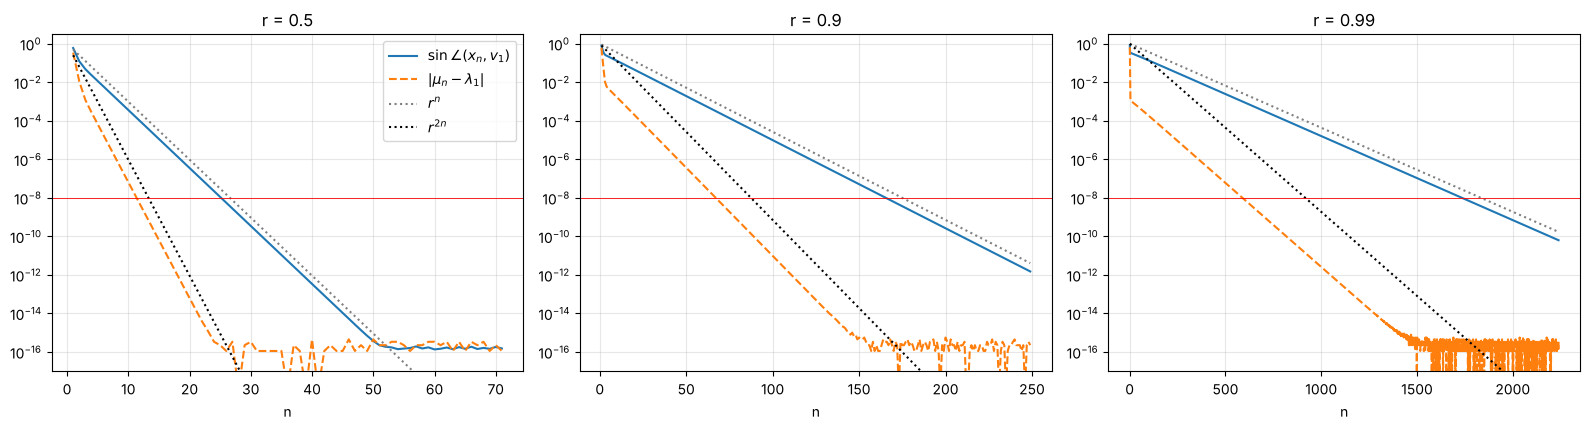

In [6]:
def power_errors(A, v1, lam1, n_steps, x0):
    """Run exactly n_steps normalised power iterations from x0.
    Returns (vec_err, eig_err): sin angle(x_n, v1) and |mu_n - lam1| for n = 1, ..., n_steps."""
    x = np.array(x0, dtype=np.result_type(A.dtype, np.float64))
    x = x / np.linalg.norm(x)
    vec_err = np.empty(n_steps)
    eig_err = np.empty(n_steps)
    for n in range(n_steps):
        y = A @ x
        x = y / np.linalg.norm(y)
        vec_err[n] = sin_angle(x, v1)
        eig_err[n] = abs(np.vdot(x, A @ x) - lam1)
    return vec_err, eig_err

def spectrum(r):
    return np.concatenate(([1.0, r], np.linspace(-0.3 * r, 0.3 * r, 48)))

def first_below(err, level):
    """first n (1-based) with err[n-1] < level, or None"""
    hit = np.flatnonzero(err < level)
    return int(hit[0]) + 1 if hit.size else None

def fitted_factor(err, hi, lo):
    """geometric per-step factor of err, fitted on the stretch where lo < err < hi"""
    idx = np.flatnonzero((err < hi) & (err > lo))
    return float(np.exp(np.polyfit(idx, np.log(err[idx]), 1)[0]))

k = 50
Q = random_orthogonal(k)
x0 = rng.standard_normal(k)
LEVEL = 1e-8

c = Q.T @ x0                                          # coordinates of x0 in the eigenbasis
print(f'x0 in the eigenbasis: c1 = {c[0]:+.3f}, c2 = {c[1]:+.3f}, |c2/c1| = {abs(c[1]/c[0]):.3f};  '
      f'initial sin(angle) = {sin_angle(x0, Q[:, 0]):.3f}\n')

radii = (0.5, 0.9, 0.99)
runs = {}
print(f"{'r':>5} | {'n_pred':>8} {'n_pred(c)':>10} | {'n_meas(vec)':>11} {'n_meas(eig)':>11} | {'factor(vec)':>11} {'factor(eig)':>11}  r, r^2")
for r in radii:
    A_r = (Q * spectrum(r)) @ Q.T                     # = Q diag(...) Q^T
    n_pred = np.log(LEVEL) / np.log(r)                # rough: sin(angle) ~ r^n
    n_pred_c = np.log(LEVEL * abs(c[0] / c[1])) / np.log(r)   # with the prefactor |c2/c1| of this x0
    n_steps = int(1.2 * max(n_pred, n_pred_c)) + 40
    ve, ee = power_errors(A_r, Q[:, 0], 1.0, n_steps, x0)
    runs[r] = (ve, ee)
    print(f'{r:5.2f} | {n_pred:8.1f} {n_pred_c:10.1f} | {first_below(ve, LEVEL):11d} {first_below(ee, LEVEL):11d} | '
          f'{fitted_factor(ve, 1e-2, 1e-12):11.4f} {fitted_factor(ee, 1e-4, 1e-13):11.4f}  {r:.4f}, {r**2:.4f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, r in zip(axes, radii):
    ve, ee = runs[r]
    n = np.arange(1, len(ve) + 1)
    ax.semilogy(n, ve, label=r'$\sin\angle(x_n, v_1)$')
    ax.semilogy(n, np.maximum(ee, 1e-18), '--', label=r'$|\mu_n-\lambda_1|$')
    ax.semilogy(n, r ** n, ':', color='gray', label=r'$r^n$')
    ax.semilogy(n, r ** (2 * n), ':', color='k', label=r'$r^{2n}$')
    ax.axhline(LEVEL, color='r', lw=0.6)
    ax.set_ylim(1e-17, 3); ax.set_xlabel('n'); ax.set_title(f'r = {r}'); ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout(); plt.show()


**(c) Two observations to explain.**
1. For this symmetric $A_r$ the eigenvalue error falls like $r^{2n}$ — twice as fast as the eigenvector error. You do not need to prove this (Module 4 will), but describe what you see and say why it is good news for PageRank-style uses.
2. Now repeat (b) for $r = 0.9$ only, with $A = P\,\mathrm{diag}(\dots)\,P^{-1}$ built by `similar_matrix`, where $P = U\,\mathrm{diag}(s)\,V^\top$ has orthogonal $U, V$ and singular values $s$ spread logarithmically from $1$ to $10^{-3}$, so that $\kappa(P) = 10^3$. Did the **rate** change? Did anything else change? Relate this to the role of $\kappa(P)$ in Lecture 3.1.

kappa(P) = 1.000e+03
||A - A^T||_F / ||A||_F = 1.41   (A is far from symmetric)

prefactor in  sin(angle) ~ C r^n :   symmetric C = 0.37,   kappa=1e3 matrix C = 0.31
                        n for sin<1e-8  n for |mu-l1|<1e-8  factor(vec)  factor(eig)
symmetric (kappa=1)                166                  68       0.9000       0.8100
kappa(P) = 1e3                     164                 136       0.9000       0.8999
error floor (largest error in the last 50 steps):  symmetric: vec 3e-16, eig 4e-16;   kappa=1e3: vec 1e-12, eig 1e-13
(r = 0.9, r^2 = 0.81)   predicted n with the prefactor: 165.4 (symmetric), 163.6 (kappa = 1e3)
prefactor C over 2000 random x0 (median, 99%, max):  symmetric [  1.03  53.02 566.69],   kappa=1e3 [1.07000e+00 6.62000e+01 1.20831e+03]
extra iterations compared with C = 1:  ln(C)/|ln r|  at the 99% level: 40;   the worst case allowed by the bound kappa(P) r^n:  ln(kappa)/|ln r| = 66


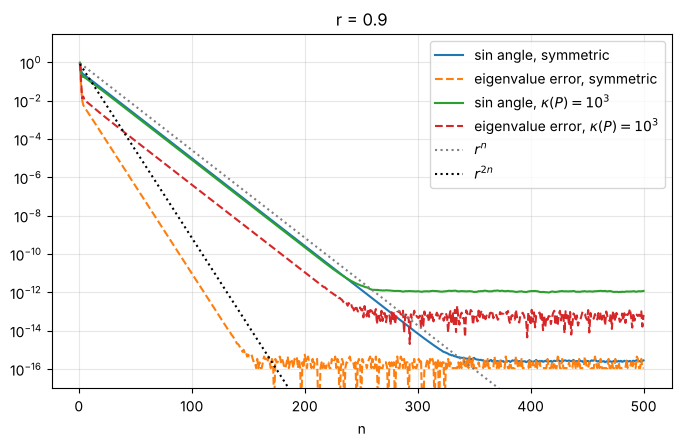

In [7]:
# (c)2: the same experiment, r = 0.9, but A = P diag(...) P^{-1} with kappa(P) = 1e3
r = 0.9
U, V = random_orthogonal(k), random_orthogonal(k)
s = np.logspace(0, -3, k)                             # singular values from 1 to 1e-3
P = (U * s) @ V.T                                     # P = U diag(s) V^T
print(f'kappa(P) = {np.linalg.cond(P):.3e}')
A_ns = similar_matrix(spectrum(r), P)                 # no inverse is formed
print(f'||A - A^T||_F / ||A||_F = {np.linalg.norm(A_ns - A_ns.T) / np.linalg.norm(A_ns):.2f}   (A is far from symmetric)')

c_ns = np.linalg.solve(P, x0)                         # coordinates of x0 in the (non-orthogonal) eigenbasis P
p1, p2 = P[:, 0], P[:, 1]
p2_perp = p2 - p1 * (p1 @ p2) / (p1 @ p1)
C_sym = abs(c[1] / c[0])
C_ns = abs(c_ns[1] / c_ns[0]) * np.linalg.norm(p2_perp) / np.linalg.norm(p1)
n_steps = 500                                          # long enough for both runs to reach their error floor
ve_ns, ee_ns = power_errors(A_ns, p1, 1.0, n_steps, x0)
A_sym = (Q * spectrum(r)) @ Q.T
ve_s, ee_s = power_errors(A_sym, Q[:, 0], 1.0, n_steps, x0)       # the symmetric reference, same x0

print(f'\nprefactor in  sin(angle) ~ C r^n :   symmetric C = {C_sym:.2f},   kappa=1e3 matrix C = {C_ns:.2f}')
W = (1e-3, 1e-9)                                       # fit the per-step factor on a clean stretch, above the error floor
print(f"{'':22s}{'n for sin<1e-8':>16s}{'n for |mu-l1|<1e-8':>20s}{'factor(vec)':>13s}{'factor(eig)':>13s}")
print(f"{'symmetric (kappa=1)':22s}{first_below(ve_s, LEVEL):16d}{first_below(ee_s, LEVEL):20d}"
      f"{fitted_factor(ve_s, *W):13.4f}{fitted_factor(ee_s, *W):13.4f}")
print(f"{'kappa(P) = 1e3':22s}{first_below(ve_ns, LEVEL):16d}{first_below(ee_ns, LEVEL):20d}"
      f"{fitted_factor(ve_ns, *W):13.4f}{fitted_factor(ee_ns, *W):13.4f}")
print(f'error floor (largest error in the last 50 steps):  symmetric: vec {ve_s[-50:].max():.0e}, eig {ee_s[-50:].max():.0e};   '
      f'kappa=1e3: vec {ve_ns[-50:].max():.0e}, eig {ee_ns[-50:].max():.0e}')
print(f'(r = {r}, r^2 = {r**2:.2f})   predicted n with the prefactor: {np.log(LEVEL / C_sym) / np.log(r):.1f} (symmetric), {np.log(LEVEL / C_ns) / np.log(r):.1f} (kappa = 1e3)')

# how large can the prefactor get?  2000 random start vectors (own generator: the lab's rng stream is not touched)
X = np.random.default_rng(7).standard_normal((k, 2000))
cs = Q.T @ X
Cs = np.abs(cs[1] / cs[0])
cn = np.linalg.solve(P, X)
Cn = np.abs(cn[1] / cn[0]) * np.linalg.norm(p2_perp) / np.linalg.norm(p1)
q = lambda v: np.round(np.percentile(v, [50, 99, 100]), 2)
print(f'prefactor C over 2000 random x0 (median, 99%, max):  symmetric {q(Cs)},   kappa=1e3 {q(Cn)}')
print(f'extra iterations compared with C = 1:  ln(C)/|ln r|  at the 99% level: {np.log(np.percentile(Cn, 99)) / abs(np.log(r)):.0f};   '
      f'the worst case allowed by the bound kappa(P) r^n:  ln(kappa)/|ln r| = {np.log(1e3) / abs(np.log(r)):.0f}')

n = np.arange(1, n_steps + 1)
plt.figure(figsize=(8, 4.6))
plt.semilogy(n, ve_s, label='sin angle, symmetric')
plt.semilogy(n, np.maximum(ee_s, 1e-18), '--', label='eigenvalue error, symmetric')
plt.semilogy(n, ve_ns, label=r'sin angle, $\kappa(P)=10^3$')
plt.semilogy(n, np.maximum(ee_ns, 1e-18), '--', label=r'eigenvalue error, $\kappa(P)=10^3$')
plt.semilogy(n, r ** n, ':', color='gray', label='$r^n$'); plt.semilogy(n, r ** (2 * n), ':', color='k', label='$r^{2n}$')
plt.ylim(1e-17, 30); plt.xlabel('n'); plt.grid(alpha=0.3); plt.legend(); plt.title('r = 0.9'); plt.show()


---
**(b) Measured against predicted** (from the table printed above; "refined" uses the prefactor $|c_2/c_1|=0.37$ of this `x0`):

| $r$ | predicted | refined | measured, $\sin\angle<10^{-8}$ | measured, $\lvert\mu_n-\lambda_1\rvert<10^{-8}$ |
|---|---|---|---|---|
| 0.5 | 26.6 | 25.1 | 26 | 12 |
| 0.9 | 174.8 | 165.4 | 166 | 68 |
| 0.99 | 1832.8 | 1733.9 | 1734 | 589 |

The fitted per-step factor of the eigenvector error is $0.5000,\ 0.9000,\ 0.9900$, i.e. exactly $r$; the prediction from the spectrum alone is right to within the (logarithmic) effect of the prefactor, and with the prefactor it is right to one iteration. The cost is dominated entirely by $r$: going from $r=0.9$ to $0.99$ multiplies the work by ten.

**(c)1. The eigenvalue error falls like $r^{2n}$.** On the three plots the dashed line (eigenvalue error) runs parallel to the dotted $r^{2n}$ line, the solid line (eigenvector error) parallel to $r^n$; the fitted factors are $r^2=0.2500,\ 0.8100,\ 0.9801$. Hence $10^{-8}$ is reached in about half the steps (12 vs 26, 68 vs 166, 589 vs 1734). The count is not exactly half because of the prefactor: $|\mu_n-\lambda_1|\approx(1-r)\,|c_2/c_1|^2\,r^{2n}$ predicts $11.4,\ 67.1,\ 588.4$ steps, against $12,\ 68,\ 589$ measured. The reason is that for a symmetric matrix the Rayleigh quotient is *stationary* at an eigenvector, so its error is the **square** of the eigenvector error.

*Why it is good news for PageRank-style uses:* any scalar that is read off the iterate through such a quadratic functional (an eigenvalue estimate, a spectral norm or growth rate, a Rayleigh-quotient energy of a graph signal) is accurate to twice as many digits as the vector itself, so one can stop after half the iterations if only that number is needed. Two cautions that matter for PageRank: the doubling needs a *symmetric* (normal) matrix — the Google matrix is not, and part (c)2 shows what is lost — and for PageRank the vector itself is the object, which converges only like $r^n$ with $r=|\lambda_2|\le$ damping factor (e.g. $\ln 10^{-8}/\ln0.85\approx113$ steps, independent of the size of the web).

**(c)2. $\kappa(P)=10^3$ (non-symmetric $A$, $r=0.9$).**
*Rate:* **unchanged** — the fitted factor of the eigenvector error is $0.9000$, and $\sin\angle<10^{-8}$ after 164 steps against 166 for the symmetric matrix (predictions with the respective prefactors: 163.6 and 165.4).
*What did change:*
1. **The eigenvalue error lost its doubling.** It now decays like $0.9^n$ (fitted factor $0.8999$, not $0.81$); $10^{-8}$ takes 136 steps instead of 68. For non-symmetric $A$ the Rayleigh quotient is no longer stationary at the eigenvector, so its error is linear in the vector error.
2. **An error floor appeared.** The symmetric run goes down to $3\cdot10^{-16}$ (eigenvector) and $4\cdot10^{-16}$ (eigenvalue); with $\kappa(P)=10^3$ the errors stop at $10^{-12}$ and $10^{-13}$, i.e. at roughly $\kappa(P)\,\varepsilon_{\rm mach}$ — the computed $A$ has eigenvectors that differ from the columns of $P$ by that much.
3. **The constant in front is allowed to be larger.** Lecture 3.1 gives $\|A^n\|\le\kappa(P)\rho(A)^n$: the geometric rate is fixed by the spectrum, and $\kappa(P)$ can only enter the *constant*. For this `x0` the prefactor is $C=0.31$ (no inflation at all). Over 2000 random start vectors the prefactor has median $1.07$ (symmetric: $1.03$), 99th percentile $66$ (symmetric $53$), maximum $1208$ (symmetric $567$) — so for typical starts $\kappa(P)$ hardly matters, while the worst case allowed by the bound, $\ln\kappa(P)/|\ln r|=66$ extra iterations, is the price of an unlucky start in a nearly dependent eigenbasis.

---

### 1.5 Reasons to fail
For each case below: explain *why* the method fails or slows down, give your own $3\times 3$ example, run `power_method` on it, and describe what you see (no convergence? convergence to the wrong thing? very slow convergence?). Look at `hist['res']` and `hist['mu']`, not only at the final output.

1. The dominant eigenvalues of a real matrix are a complex-conjugate pair.
2. $\lambda_1 = -\lambda_2$ (two real eigenvalues of equal modulus).
3. The dominant eigenvalue is defective: a Jordan block. *Hint:* it does converge — at what rate? Compare with the asymptotics $n^k|\lambda|^n$ from Lecture 3.1. Plot the eigenvector error, the eigenvalue error and the residual against $n$; they do **not** fall at the same rate. What does that tell you about trusting a small residual?
4. The starting vector has $c_1 = 0$. First run `power_method` with its defaults on $A = Q\,\mathrm{diag}(2,1,0.5)\,Q^\top$ (random orthogonal $Q$) and $\mathbf{x}_0 = \mathbf{q}_2$: why does it stop at once, and with what answer? Then switch the stopping test off (`tol=0`, `max_iter=120`) and compare two runs: $A = \mathrm{diag}(2, 1, 0.5)$ with $\mathbf{x}_0 = \mathbf{e}_2$, and $QDQ^\top$ with $\mathbf{x}_0 = \mathbf{q}_2$. They behave differently. Explain why, and predict roughly how many iterations the second one needs before it "notices" $\mathbf{v}_1$.

eigenvalues of A_c (check only): [0.5+0.j  1.2+1.6j 1.2-1.6j]
iterations: 300 (= max_iter, no convergence);  last mu = 1.200000,  last residuals = [1.6 1.6 1.6]
expected:  Re(lambda) = 1.2,   |Im(lambda)| = 1.6,   rotation angle = atan2(1.6, 1.2) = 53.13 deg
angle between consecutive iterates: 53.13 deg


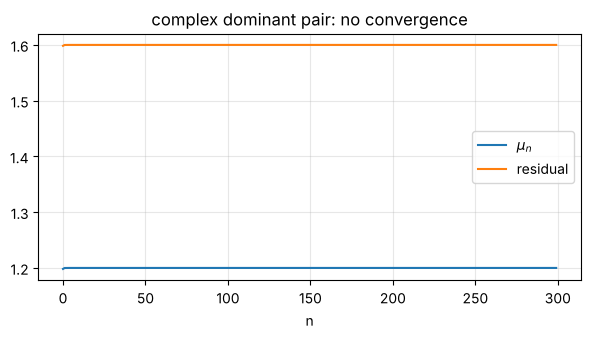

In [8]:
# --- Failure 1: a complex-conjugate pair is dominant: eigenvalues 1.2 +- 1.6i (modulus 2) and 0.5 ---
B1 = np.array([[1.2, -1.6, 0.0], [1.6, 1.2, 0.0], [0.0, 0.0, 0.5]])
Q3 = random_orthogonal(3)
A_c = Q3 @ B1 @ Q3.T
x0_c = rng.standard_normal(3)
print('eigenvalues of A_c (check only):', np.round(np.linalg.eigvals(A_c), 4))
mu, x, hist = power_method(A_c, x0_c, tol=1e-10, max_iter=300)
print(f'iterations: {len(hist["res"])} (= max_iter, no convergence);  last mu = {hist["mu"][-1].real:.6f},  last residuals = {np.round(hist["res"][-3:], 6)}')
print('expected:  Re(lambda) = 1.2,   |Im(lambda)| = 1.6,   rotation angle = atan2(1.6, 1.2) = %.2f deg' % np.degrees(np.arctan2(1.6, 1.2)))
_, xa, _ = power_method(A_c, x0_c, tol=0, max_iter=200)
_, xb, _ = power_method(A_c, x0_c, tol=0, max_iter=201)
print('angle between consecutive iterates: %.2f deg' % np.degrees(np.arcsin(sin_angle(xa, xb))))
plt.figure(figsize=(7, 3.2))
plt.plot(hist['mu'].real, label=r'$\mu_n$'); plt.plot(hist['res'], label='residual'); plt.xlabel('n'); plt.legend(); plt.grid(alpha=0.3)
plt.title('complex dominant pair: no convergence'); plt.show()


---
**Failure 1 — dominant complex pair** (`A_c`$=Q\,B\,Q^\top$ with $B=\begin{pmatrix}1.2&-1.6\\1.6&1.2\end{pmatrix}\oplus(0.5)$, eigenvalues $1.2\pm1.6i$ of modulus $2$, and $0.5$).

*Why it fails.* $A^n\mathbf x_0=2^n\bigl(c\,e^{in\theta}\mathbf w+\bar c\,e^{-in\theta}\bar{\mathbf w}\bigr)+O(0.5^n)$ with $\theta=\arg(1.2+1.6i)=53.13^\circ$: after the third component has died, the iterate is a real vector that **rotates by $\theta$ in the invariant plane** at every step. There is no real eigenvector to approach, and $|\lambda_2/\lambda_1|=1$.

*What we see.* 300 iterations without convergence; consecutive iterates are exactly $53.13^\circ$ apart; the residual sits at $1.6=|{\rm Im}\,\lambda|$ for ever; the Rayleigh quotient settles at $1.2={\rm Re}\,\lambda$, which is **not an eigenvalue** — it "converges to the wrong thing", and only the residual reveals it. (A real shift cannot help: $\lambda$ and $\bar\lambda$ stay equally far from any real shift. Use a complex shift in inverse iteration (§2), or the QR algorithm (extension A1).)

---

iterations: 300 (= max_iter);  last four mu = [1.959775 2.034217 1.959775 2.034217]
                                last four residuals = [0.113591 0.117906 0.113591 0.117906]
sin angle(x_200, x_201) = 0.0579   but   sin angle(x_200, x_202) = 4.6e-16   -> period 2
power_method on A + I: mu - 1 = 2.0000000235  after 26 iterations (lambda_1 = 2 recovered)


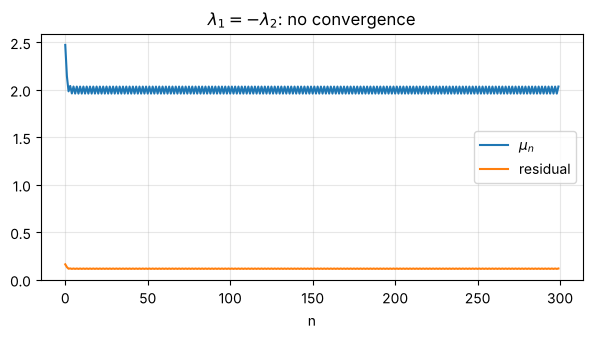

In [9]:
# --- Failure 2: lambda_1 = -lambda_2: eigenvalues 2, -2, 0.5 (A is not symmetric) ---
P3 = rng.standard_normal((3, 3))
A_o = similar_matrix([2.0, -2.0, 0.5], P3)
x0_o = rng.standard_normal(3)
mu, x, hist = power_method(A_o, x0_o, tol=1e-10, max_iter=300)
print(f'iterations: {len(hist["res"])} (= max_iter);  last four mu = {np.round(hist["mu"][-4:], 6)}')
print(f'                                last four residuals = {np.round(hist["res"][-4:], 6)}')
xs = [power_method(A_o, x0_o, tol=0, max_iter=m)[1] for m in (200, 201, 202)]
print(f'sin angle(x_200, x_201) = {sin_angle(xs[0], xs[1]):.4f}   but   sin angle(x_200, x_202) = {sin_angle(xs[0], xs[2]):.1e}   -> period 2')
# a spectral shift cures this case: A + I has eigenvalues 3, -1, 1.5
mu_s, x_s, hist_s = power_method(A_o + np.eye(3), x0_o)
print(f'power_method on A + I: mu - 1 = {mu_s - 1:.10f}  after {len(hist_s["res"])} iterations (lambda_1 = 2 recovered)')
plt.figure(figsize=(7, 3.2))
plt.plot(hist['mu'], label=r'$\mu_n$'); plt.plot(hist['res'], label='residual'); plt.xlabel('n'); plt.legend(); plt.grid(alpha=0.3)
plt.title(r'$\lambda_1=-\lambda_2$: no convergence'); plt.show()


---
**Failure 2 — $\lambda_1=-\lambda_2$** (`A_o`$=P\,{\rm diag}(2,-2,0.5)\,P^{-1}$, not symmetric).

*Why it fails.* $A^n\mathbf x_0=2^n\bigl(c_1\mathbf v_1+(-1)^nc_2\mathbf v_2\bigr)+O(0.25^n)$: the two dominant components keep the same size and only the sign of one of them changes, so $\mathbf x_n$ **alternates between two directions** and never settles.

*What we see.* No convergence in 300 iterations; $\sin\angle(\mathbf x_{200},\mathbf x_{201})=0.058$ but $\sin\angle(\mathbf x_{200},\mathbf x_{202})=4.6\cdot10^{-16}$ — period 2. The Rayleigh quotient alternates between $1.9598$ and $2.0342$, i.e. it *looks* like an approximation of $\lambda_1=2$ to within 2 %, yet it is not converging to anything and the residual stays at $0.114/0.118$. This is the case in which looking only at $\mu_n$ would mislead; `hist['res']` does not. A spectral shift cures it: $A+I$ has eigenvalues $3,-1,1.5$ and `power_method(A + I)` converges in 26 iterations to $\lambda_1+1$ (the printed $\mu-1=2.0000000235$).

---

log-log slopes for n >= 100:  eigenvector error -0.998,  eigenvalue error -0.998,  residual -1.996


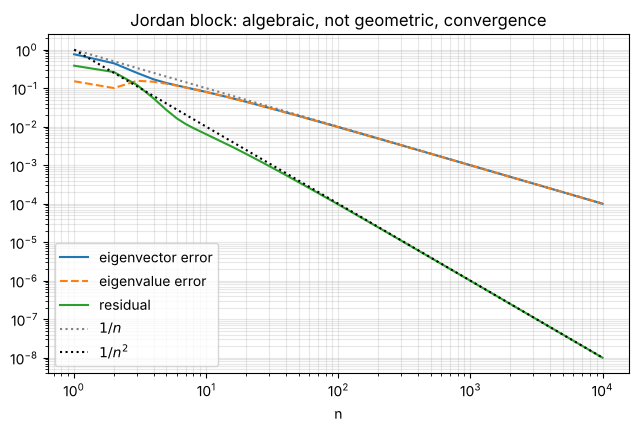

default tol: stops after 74476 iterations with residual 1.80e-10  (< 1e-10 ||J||_F = 1.80e-10)
   but eigenvector error = 1.34e-05  and eigenvalue error = 1.34e-05   (sqrt(residual) = 1.34e-05)


In [10]:
# --- Failure 3: the dominant eigenvalue is defective: J_2(1) + [0.5] ---
J = np.array([[1.0, 1.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 0.5]])
e1 = np.array([1.0, 0.0, 0.0])
x0_j = rng.standard_normal(3)
N = 10_000
ve_j, ee_j = power_errors(J, e1, 1.0, N, x0_j)
_, _, hist_j = power_method(J, x0_j, tol=0, max_iter=N)          # tol = 0: run all N steps
res_j = hist_j['res']
n = np.arange(1, N + 1)
slope = lambda err: np.polyfit(np.log(n[100:]), np.log(err[100:]), 1)[0]
print(f'log-log slopes for n >= 100:  eigenvector error {slope(ve_j):+.3f},  eigenvalue error {slope(ee_j):+.3f},  residual {slope(res_j):+.3f}')

plt.figure(figsize=(7.5, 4.4))
plt.loglog(n, ve_j, label='eigenvector error'); plt.loglog(n, ee_j, '--', label='eigenvalue error'); plt.loglog(n, res_j, label='residual')
plt.loglog(n, 1 / n, ':', color='gray', label='$1/n$'); plt.loglog(n, 1 / n ** 2, ':', color='k', label='$1/n^2$')
plt.xlabel('n'); plt.grid(alpha=0.3, which='both'); plt.legend(); plt.title('Jordan block: algebraic, not geometric, convergence'); plt.show()

mu_j, x_j, h = power_method(J, x0_j, tol=1e-10, max_iter=10**6)   # the default stopping rule, run to the end
print(f'default tol: stops after {len(h["res"])} iterations with residual {h["res"][-1]:.2e}  (< 1e-10 ||J||_F = {1e-10 * np.linalg.norm(J, "fro"):.2e})')
print(f'   but eigenvector error = {sin_angle(x_j, e1):.2e}  and eigenvalue error = {abs(mu_j - 1):.2e}   (sqrt(residual) = {np.sqrt(h["res"][-1]):.2e})')


---
**Failure 3 — defective dominant eigenvalue** ($J=J_2(1)\oplus(0.5)$: $\lambda=1$ has algebraic multiplicity 2 but only one eigenvector $\mathbf e_1$).

*Why it is slow.* $J_2(1)^n=\begin{pmatrix}1&n\\0&1\end{pmatrix}$, so $A^n\mathbf x_0\approx(a+nb,\;b,\;0.5^nc)^\top$ and the direction approaches $\mathbf e_1$ at the angle $\approx b/(a+nb)\approx1/n$. This is the $n^{k}|\lambda|^n$ asymptotics of Lecture 3.1 with $k=1$: the polynomial factor $n$ in the *eigenvector* component is what slowly beats the generalised-eigenvector component, instead of a geometric $(\lambda_2/\lambda_1)^n$.

*What we see* (log–log plot, slopes fitted for $n\ge100$): eigenvector error $\sim n^{-0.998}$, eigenvalue error $\sim n^{-0.998}$, residual $\sim n^{-1.996}$ — i.e. $1/n,\ 1/n,\ 1/n^2$. The method **does** converge, but algebraically; the three quantities do not fall at the same rate.

*What this says about trusting a small residual.* With the default test it stops only after 74 476 iterations, with residual $1.8\cdot10^{-10}$ — but the eigenvector error and the eigenvalue error are then $1.34\cdot10^{-5}=\sqrt{\text{residual}}$. For a defective (and, in general, non-normal) matrix a small residual certifies only a *tiny backward error*: the pair is an exact eigenpair of $A+E$ with $\|E\|\approx$ residual, and a Jordan eigenvalue moves by $\sqrt{\|E\|}$ under such a perturbation. So the residual is the right stopping test (it does not depend on signs or on knowing the answer), but it does not bound the forward error unless $A$ is well-behaved (normal).

---

defaults, x0 = q2:  stops after 1 iteration(s) with mu = 1.000000000000, residual 8.7e-16, sin angle(x, q2) = 5.0e-16

A = diag(2,1,.5), x0 = e2   : after 120 steps mu = 1.000000000000, residual 0.0e+00   (never leaves e2)
A = Q D Q^T,      x0 = q2   : after 120 steps mu = 2.000000000000, residual 2.5e-16
   mu leaves 1 (by more than 1e-3) at n = 47,   is within 1e-6 of 2 from n = 62
   prediction: ln(1/eps)/ln(lambda_1/lambda_2) = ln(1e16)/ln 2 = 53.2   (eps ~ 1e-16 = rounding level)
   initial overlap of x0 with v_1 = q_1: |q1.q2| = 1.7e-16


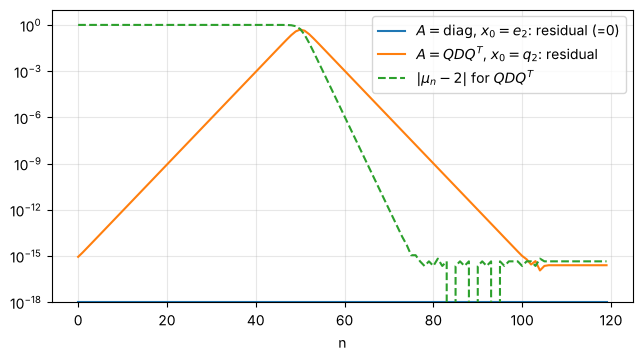

In [11]:
# --- Failure 4: the starting vector has c_1 = 0 ---
Q3b = random_orthogonal(3)
D3 = np.array([2.0, 1.0, 0.5])
A_d = (Q3b * D3) @ Q3b.T
q2 = Q3b[:, 1]
mu, x, hist = power_method(A_d, x0=q2)                # defaults
print(f'defaults, x0 = q2:  stops after {len(hist["res"])} iteration(s) with mu = {mu:.12f}, residual {hist["res"][-1]:.1e}, '
      f'sin angle(x, q2) = {sin_angle(x, q2):.1e}')

mu_a, xa, ha = power_method(np.diag(D3), x0=np.array([0.0, 1.0, 0.0]), tol=0, max_iter=120)
mu_b, xb, hb = power_method(A_d, x0=q2, tol=0, max_iter=120)
print(f'\nA = diag(2,1,.5), x0 = e2   : after 120 steps mu = {mu_a:.12f}, residual {ha["res"][-1]:.1e}   (never leaves e2)')
print(f'A = Q D Q^T,      x0 = q2   : after 120 steps mu = {mu_b:.12f}, residual {hb["res"][-1]:.1e}')
leave = int(np.flatnonzero(np.abs(hb['mu'] - 1) > 1e-3)[0]) + 1
arrive = int(np.flatnonzero(np.abs(hb['mu'] - 2) < 1e-6)[0]) + 1
print(f'   mu leaves 1 (by more than 1e-3) at n = {leave},   is within 1e-6 of 2 from n = {arrive}')
print(f'   prediction: ln(1/eps)/ln(lambda_1/lambda_2) = ln(1e16)/ln 2 = {np.log(1e16) / np.log(2):.1f}   (eps ~ 1e-16 = rounding level)')
print(f'   initial overlap of x0 with v_1 = q_1: |q1.q2| = {abs(Q3b[:, 0] @ q2):.1e}')

plt.figure(figsize=(7.5, 3.8))
plt.semilogy(ha['res'] + 1e-18, label=r'$A=\mathrm{diag}$, $x_0=e_2$: residual (=0)')
plt.semilogy(hb['res'], label=r'$A=QDQ^T$, $x_0=q_2$: residual')
plt.semilogy(np.abs(hb['mu'] - 2), '--', label=r'$|\mu_n-2|$ for $QDQ^T$')
plt.xlabel('n'); plt.legend(); plt.grid(alpha=0.3); plt.ylim(1e-18, 10); plt.show()


---
**Failure 4 — $c_1=0$** ($A=Q\,{\rm diag}(2,1,0.5)\,Q^\top$, $\mathbf x_0=\mathbf q_2$).

*Defaults.* `power_method` stops after **one** iteration with $\mu=1.000000000000$ and $\mathbf x=\pm\mathbf q_2$ (residual $8.7\cdot10^{-16}$). The start vector already *is* an eigenvector, so the residual is zero up to rounding: the test certifies **an** eigenpair, not the **dominant** one (here it returns the middle eigenvalue).

*Stopping test off* (`tol=0`, 120 steps; `<` is strict, so `tol=0` never triggers):
* $A={\rm diag}(2,1,0.5)$, $\mathbf x_0=\mathbf e_2$: the arithmetic is **exact** (multiplying by $2,\,1,\,0.5$ and $0$ is exact in floating point), the component along $\mathbf e_1$ is exactly $0$ for ever; after 120 steps $\mu=1$ and the residual is exactly $0.0$ — the method never leaves $\mathbf e_2$.
* $A=QDQ^\top$, $\mathbf x_0=\mathbf q_2$: forming $A$ and multiplying by it introduces rounding errors of relative size $10^{-16}$; indeed $|\mathbf q_1^\top\mathbf q_2|=1.7\cdot10^{-16}$. That tiny component along $\mathbf v_1$ is multiplied by $\lambda_1/\lambda_2=2$ **relative to the main component** at every step, so the method "notices" $\mathbf v_1$ when $2^n\cdot10^{-16}\approx1$:
$$n\approx\frac{\ln10^{16}}{\ln2}\approx53.$$
Measured: $\mu_n$ leaves $1$ by more than $10^{-3}$ at $n=47$ (when the weight of $\mathbf v_1$ is about $0.03$: $\log_2(0.03/1.7\cdot10^{-16})\approx47$), is within $10^{-6}$ of $2$ from $n=62$, and after 120 steps $\mu=2$ with residual $2.5\cdot10^{-16}$.

*Moral.* A start vector with $c_1=0$ is saved by rounding errors, but only after about 50 wasted iterations, and not at all when zeros are exactly preserved (diagonal or block-structured matrices, zero entries in a sparse start vector, a reducible graph). In practice one starts with a random vector.

---

---
## 2. Inverse iteration with a shift

### 2.1 The idea
If $A\mathbf{v} = \lambda\mathbf{v}$ then $(A - \mu I)^{-1}\mathbf{v} = (\lambda - \mu)^{-1}\mathbf{v}$. So the eigenvalue of $A$ **closest to the shift** $\mu$ becomes the *dominant* eigenvalue of $(A-\mu I)^{-1}$, and power iteration on $(A-\mu I)^{-1}$ finds it. The per-step rate is
$$
\frac{|\lambda_* - \mu|}{|\lambda_{**} - \mu|},
$$
where $\lambda_*$ is the closest eigenvalue and $\lambda_{**}$ the second-closest.

You never form $(A-\mu I)^{-1}$. Each step **solves** $(A - \mu I)\mathbf{y} = \mathbf{x}_{n-1}$. Factorise $A - \mu I = LU$ once with `scipy.linalg.lu_factor`, then call `scipy.linalg.lu_solve` at every step.

### 2.2 Implement `inverse_iteration`
Return the eigenvalue **of $A$** (the Rayleigh quotient $\mathbf{x}^*A\mathbf{x}$, not of the inverse), the unit eigenvector and the same history as before, with the same residual stopping rule applied to $A$.

In [12]:
def inverse_iteration(A, mu, x0=None, tol=1e-10, max_iter=500):
    """
    Eigenpair of A for the eigenvalue closest to the shift mu.
    One LU factorisation of A - mu I, reused at every step.
    Returns (lam, x, hist) as in power_method; lam is an eigenvalue of A (Rayleigh quotient x* A x),
    and the stopping test is ||A x - lam x|| < tol * ||A||_F, exactly as in power_method.
    """
    A = np.asarray(A)
    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError('A must be square')
    k = A.shape[0]
    dtype = np.result_type(A.dtype, np.asarray(mu).dtype, np.float64)
    x = rng.standard_normal(k).astype(dtype) if x0 is None else np.array(x0, dtype=dtype)
    nrm = np.linalg.norm(x)
    if nrm == 0.0:
        raise ValueError('the starting vector is zero')
    x = x / nrm
    stop_level = tol * np.linalg.norm(A, 'fro')

    lu_piv = sla.lu_factor(A - mu * np.eye(k))        # the ONLY factorisation: (2/3) k^3 flops
    lams, ress = [], []
    lam = 0.0
    for _ in range(max_iter):
        y = sla.lu_solve(lu_piv, x)                   # solves (A - mu I) y = x : 2 k^2 flops
        ny = np.linalg.norm(y)
        if not np.isfinite(ny) or ny == 0.0:
            raise ValueError('A - mu I is singular to working precision: move the shift off the eigenvalue a little')
        x = y / ny
        Ax = A @ x
        lam = np.vdot(x, Ax)                          # eigenvalue of A, not of the inverse
        res = np.linalg.norm(Ax - lam * x)
        lams.append(lam); ress.append(res)
        if res < stop_level:
            break
    return lam, x, {'mu': np.array(lams), 'res': np.array(ress)}


**Question 2.2.** State the cost of your implementation in flops, to leading order, for a $k\times k$ matrix and $m$ iterations. Compare with (i) calling `np.linalg.solve(A - mu*I, x)` inside the loop and (ii) forming `inv(A - mu*I)` once and multiplying. Why is (ii) still worse than your version, even though its cost per step is also $O(k^2)$?

---
**Cost** (leading order, $A$ is $k\times k$, $m$ iterations).

* **Mine:** one LU factorisation of $A-\mu I$: $\tfrac23k^3$ flops. Each iteration: two triangular solves (`lu_solve`), $k^2+k^2=2k^2$ flops, plus one product $A\mathbf x$ for the Rayleigh quotient and the residual, another $2k^2$. Total $\;\tfrac23k^3+4mk^2$ (the solves alone: $\tfrac23k^3+2mk^2$).
* **(i)** `np.linalg.solve(A - mu*I, x)` inside the loop refactorises every time: $m\bigl(\tfrac23k^3+2k^2\bigr)+2mk^2\approx\tfrac23mk^3$ — **$m$ times more cubic work**. With the $m=22$ to $450$ iterations seen in §2.3 this is a factor of that size in the dominant term.
* **(ii)** forming the inverse once and multiplying: $\approx2k^3$ flops for the inverse (3 times the cost of the LU factorisation), then $2k^2$ per product $+\,2k^2$ for the residual, i.e. $2k^3+4mk^2$. (`np.linalg.inv` is forbidden in this notebook, so (ii) is not run.)

**Why (ii) is still worse than mine**, although its cost per step is also $O(k^2)$ (a product with $A^{-1}$ costs $2k^2$, exactly like the two triangular solves):
1. the set-up is three times as expensive, $2k^3$ against $\tfrac23k^3$;
2. **accuracy:** LU with partial pivoting is backward stable — the computed $\mathbf y$ satisfies $(M+E)\mathbf y=\mathbf x$ with $\|E\|\sim\varepsilon\|M\|$ — whereas multiplying by a *computed* inverse is not: its residual $\|M\hat{\mathbf y}-\mathbf x\|$ can be as large as $\kappa(M)\varepsilon\|M\|\|\hat{\mathbf y}\|$. Inverse iteration works with shifts for which $\kappa(M)$ is huge by design (§2.4), so this is precisely the regime where the inverse is untrustworthy;
3. **structure:** for a sparse or banded $A$ the factors $L,U$ stay (nearly) sparse, while $M^{-1}$ is a full matrix with $k^2$ entries.

---

### 2.3 Find all eigenvalues of a test matrix
Let $D = \mathrm{diag}(0, 1, \dots, 9)$, let $P$ be a random $10\times10$ matrix, and $A = PDP^{-1}$ (use `similar_matrix`).

**(a)** Explain why the diagonal entries of $D$ are the eigenvalues of $A$ and the columns of $P$ are corresponding eigenvectors.

**(b)** With the shifts $\mu_j = j + 0.3$, $j = 0,\dots,9$, find all ten eigenpairs. Check each against the corresponding column of $P$ with `sin_angle`.

**(c)** Predict the per-step rate for $\mu = j + 0.3$ and for $\mu = j + 0.49$, then measure both for one $j$ of your choice from the history. Which eigenvalue does $\mu = j + 0.5$ find, and why is that shift a bad idea?

---
**(a)** `similar_matrix` builds $A$ so that $AP=PD$. Comparing column $j$ on both sides gives $A\mathbf p_j=d_j\mathbf p_j$ with $\mathbf p_j\ne\mathbf 0$ (a column of an invertible matrix), so every $d_j=j$ is an eigenvalue of $A$ with eigenvector $\mathbf p_j$. A random Gaussian $10\times10$ matrix is invertible with probability 1 (here $\kappa(P)=52.4$), so the columns of $P$ are 10 linearly independent eigenvectors; equivalently $A=PDP^{-1}$ is similar to $D$, has the same characteristic polynomial $\prod(\lambda-j)$, and its spectrum is exactly $\{0,1,\dots,9\}$ — ten distinct eigenvalues, so each eigenspace is the line spanned by one $\mathbf p_j$.

---

In [13]:
D_vals = np.arange(10.)
P10 = rng.standard_normal((10, 10))
A10 = similar_matrix(D_vals, P10)
print(f'kappa(P) = {np.linalg.cond(P10):.1f},   ||A||_F = {np.linalg.norm(A10, "fro"):.1f},   '
      f'eigenvalues of A (check only): {np.round(np.sort(np.linalg.eigvals(A10).real), 6)}')

# (b) all ten eigenpairs with the shifts mu_j = j + 0.3
print(f"\n{'j':>2} {'shift':>6} | {'lambda found':>14} {'|lambda-j|':>10} {'sin angle to P[:, j]':>21} | {'iters':>5} {'q predicted':>11} {'q measured':>10}")
for j in range(10):
    shift = j + 0.3
    lam, x, hist = inverse_iteration(A10, shift, tol=1e-12)
    d = np.sort(np.abs(D_vals - shift))
    q_pred = d[0] / d[1]
    r = hist['res']
    q_meas = np.exp(np.mean(np.diff(np.log(r[len(r)//2:])))) if len(r) > 4 else np.nan
    print(f'{j:2d} {shift:6.2f} | {lam.real:14.10f} {abs(lam - j):10.1e} {sin_angle(x, P10[:, j]):21.1e} | {len(r):5d} {q_pred:11.4f} {q_meas:10.4f}')


kappa(P) = 52.4,   ||A||_F = 77.9,   eigenvalues of A (check only): [-0.  1.  2.  3.  4.  5.  6.  7.  8.  9.]

 j  shift |   lambda found |lambda-j|  sin angle to P[:, j] | iters q predicted q measured
 0   0.30 |   0.0000000000    2.2e-11               5.9e-11 |    29      0.4286     0.4286


 1   1.30 |   1.0000000000    2.1e-11               4.6e-11 |    24      0.4286     0.4285
 2   2.30 |   2.0000000000    3.7e-12               7.4e-11 |    28      0.4286     0.4286
 3   3.30 |   3.0000000000    5.0e-11               4.8e-11 |    27      0.4286     0.4286
 4   4.30 |   4.0000000000    6.8e-13               6.3e-11 |    26      0.4286     0.4286
 5   5.30 |   5.0000000000    8.5e-12               5.3e-11 |    30      0.4286     0.4286
 6   6.30 |   6.0000000000    6.1e-12               6.8e-11 |    27      0.4286     0.4286
 7   7.30 |   7.0000000000    2.2e-11               5.6e-11 |    26      0.4286     0.4286
 8   8.30 |   8.0000000000    1.8e-11               5.3e-11 |    27      0.4286     0.4286
 9   9.30 |   9.0000000000    8.0e-12               2.3e-11 |    20      0.2308     0.2308


---
**(b)** All ten eigenpairs are found: $|\lambda-j|\le5\cdot10^{-11}$ and $\sin\angle(\mathbf x,\mathbf p_j)\le8\cdot10^{-11}$, after 20–30 iterations each. (The accuracy is set by the stopping level $10^{-12}\|A\|_F=7.8\cdot10^{-11}$.) The measured per-step factor of the residual agrees with the predicted $|\lambda_*-\mu|/|\lambda_{**}-\mu|$ to three digits: $0.3/0.7=0.4286$ for $j=0,\dots,8$, and $0.3/1.3=0.2308$ for $j=9$, where the second-closest eigenvalue is on the other side and farther away (and, accordingly, only 20 iterations are needed).

---

In [14]:
# (c): per-step rate for shifts j + 0.3, j + 0.49 and j + 0.5, here j = 4; the same x0 for all three
j = 4
x0_i = rng.standard_normal(10)
print(f"{'shift':>6} | {'q predicted':>11} {'q measured':>10} | {'iters needed':>12} {'predicted':>9} | converged?   final lambda")
for shift, mx in ((j + 0.3, 3000), (j + 0.49, 3000), (j + 0.5, 3000)):
    lam, x, hist = inverse_iteration(A10, shift, x0=x0_i, tol=1e-10, max_iter=mx)
    r = hist['res']
    d = np.sort(np.abs(D_vals - shift)); q_pred = d[0] / d[1]
    q_meas = np.exp(np.mean(np.diff(np.log(r[len(r)//2:])))) if len(r) > 4 and q_pred < 1 else np.nan
    stop = 1e-10 * np.linalg.norm(A10, 'fro')
    n_pred = np.log(stop / r[0]) / np.log(q_pred) if q_pred < 1 else np.inf
    conv = r[-1] < stop
    print(f'{shift:6.2f} | {q_pred:11.4f} {q_meas:10.4f} | {len(r):12d} {n_pred:9.1f} | {str(conv):10s}   {lam.real:.6f}')
    if q_pred == 1.0 or not conv:
        print('         last residuals:', np.array2string(r[-4:], precision=3), '   last Rayleigh quotients:', np.array2string(hist['mu'][-4:].real, precision=4))


 shift | q predicted q measured | iters needed predicted | converged?   final lambda
  4.30 |      0.4286     0.4285 |           22      19.7 | True         4.000000
  4.49 |      0.9608     0.9608 |          449     420.6 | True         4.000000
  4.50 |      1.0000        nan |         3000       inf | False        4.191961
         last residuals: [0.393 0.399 0.393 0.399]    last Rayleigh quotients: [4.1971 4.192  4.1971 4.192 ]


---
**(c)** Here $j=4$, one common start vector.

| shift | predicted factor | measured factor | iterations to $10^{-10}\|A\|_F$ | predicted | outcome |
|---|---|---|---|---|---|
| 4.30 | $0.3/0.7=0.4286$ | 0.4285 | 22 | 19.7 | $\lambda=4$ |
| 4.49 | $0.49/0.51=0.9608$ | 0.9608 | 449 | 420.6 | $\lambda=4$ |
| 4.50 | $0.5/0.5=1$ | — | not converged after 3000 | $\infty$ | neither |

(The predicted iteration counts $\ln(\text{stop}/r_1)/\ln q$ are slightly low because they ignore the initial transient.) Moving the shift from $j+0.3$ to $j+0.49$ makes the factor go from $0.43$ to $0.96$ and the cost from 22 to 449 iterations: the rate depends on the distance to the closest eigenvalue *relative to* the distance to the second closest.

**$\mu=j+0.5$ finds no eigenvalue.** The eigenvalues $j$ and $j+1$ are exactly equally distant, so $(A-\mu I)^{-1}$ has the two dominant eigenvalues $1/(j-\mu)=-2$ and $1/(j+1-\mu)=+2$: this is failure 2 of §1.5 ($\lambda_1=-\lambda_2$) for the inverse operator. The iterate alternates between two directions (mixtures of $\mathbf p_4$ and $\mathbf p_5$), the Rayleigh quotient alternates between $4.1971$ and $4.1920$ — neither $4$ nor $5$ — and the residual stays at $0.39$–$0.40$. It is a bad idea because a shift at the midpoint gives rate exactly $1$; in general a shift should be as close as possible to the target and far from all other eigenvalues.

---

### 2.4 A shift that is *too* good
Take $\mu = 4 + 10^{-12}$. Compute $\kappa(A_{10} - \mu I)$ with `np.linalg.cond`. By everything you learned in Modules 1–2, solving with this matrix should be hopeless. Run `inverse_iteration` anyway and report the number of iterations and the accuracy of the eigenvector. Then explain, in your own words, why the huge condition number does no harm here. *(Hint: the solution $\mathbf{y}$ is badly wrong in length; in which direction is it wrong?)*

In [15]:
mu24 = 4 + 1e-12
M24 = A10 - mu24 * np.eye(10)
print(f'cond(A10 - mu I) = {np.linalg.cond(M24):.3e}')
x0_24 = rng.standard_normal(10)
lam, x, hist = inverse_iteration(A10, mu24, x0=x0_24, tol=1e-10)
print(f'iterations: {len(hist["res"])};  residuals: {np.array2string(hist["res"], precision=2)}')
print(f'eigenvalue error |lam - 4| = {abs(lam - 4):.1e};   eigenvector error sin angle(x, P10[:, 4]) = {sin_angle(x, P10[:, 4]):.1e}')

# What does the single solve really do?  Compare the float64 solution with the EXACT solution of the same
# system (rational arithmetic from the standard library: the float entries are converted exactly).
from fractions import Fraction
def exact_solve(M, b):
    n = len(b)
    T = [[Fraction(float(M[i, j])) for j in range(n)] + [Fraction(float(b[i]))] for i in range(n)]
    for c in range(n):
        p = max(range(c, n), key=lambda i: abs(T[i][c]))
        T[c], T[p] = T[p], T[c]
        for i in range(c + 1, n):
            f = T[i][c] / T[c][c]
            T[i] = [u - f * w for u, w in zip(T[i], T[c])]
    y = [Fraction(0)] * n
    for i in range(n - 1, -1, -1):
        y[i] = (T[i][n] - sum(T[i][j] * y[j] for j in range(i + 1, n))) / T[i][i]
    return np.array([float(t) for t in y])

xs0 = x0_24 / np.linalg.norm(x0_24)
y_exact = exact_solve(M24, xs0)
y_float = sla.lu_solve(sla.lu_factor(M24), xs0)
v_dir = y_exact / np.linalg.norm(y_exact)
err_vec = y_float - y_exact
print(f'\nsolve of (A - mu I) y = x_0:   ||y|| = {np.linalg.norm(y_exact):.2e}')
print(f'   relative error of y                 ||y_float - y|| / ||y|| = {np.linalg.norm(err_vec) / np.linalg.norm(y_exact):.1e}   (kappa * eps = {np.linalg.cond(M24) * np.finfo(float).eps:.1e})')
print(f'   part of that error along y itself   {abs(err_vec @ v_dir) / np.linalg.norm(y_exact):.1e}')
print(f'   part perpendicular to y             {np.linalg.norm(err_vec - (err_vec @ v_dir) * v_dir) / np.linalg.norm(y_exact):.1e}  (this is the error in the DIRECTION)')
print(f'   direction of y_float vs exact: sin angle = {sin_angle(y_float, y_exact):.1e}')


cond(A10 - mu I) = 3.792e+14
iterations: 1;  residuals: [9.18e-13]
eigenvalue error |lam - 4| = 1.0e-12;   eigenvector error sin angle(x, P10[:, 4]) = 5.3e-12

solve of (A - mu I) y = x_0:   ||y|| = 1.09e+12
   relative error of y                 ||y_float - y|| / ||y|| = 9.1e-04   (kappa * eps = 8.4e-02)
   part of that error along y itself   9.1e-04
   part perpendicular to y             4.7e-15  (this is the error in the DIRECTION)
   direction of y_float vs exact: sin angle = 4.7e-15


---
**What we see.** With $\mu=4+10^{-12}$: $\kappa(A_{10}-\mu I)=3.8\cdot10^{14}$ (the matrix is numerically singular), and `inverse_iteration` stops after **1 iteration** (residual $9.2\cdot10^{-13}$): the eigenvalue is accurate to $1.0\cdot10^{-12}$ and the eigenvector to $\sin\angle=5.3\cdot10^{-12}$.

**Why the condition number does no harm.** The cell compares the floating-point solution of $(A-\mu I)\mathbf y=\mathbf x_0$ with a 60-digit solution of the same system:
* $\|\mathbf y\|=1.1\cdot10^{12}$: the solution is enormous, because $\mathbf y=\sum_ic_i(\lambda_i-\mu)^{-1}\mathbf v_i$ and the term with $\lambda_i-\mu=-10^{-12}$ is $10^{12}$ times larger than the others — **$\mathbf y$ is already a multiple of the eigenvector $\mathbf v$ to within $10^{-12}$**;
* its relative error is $9.1\cdot10^{-4}$ (the textbook bound $\kappa\varepsilon=8.4\cdot10^{-2}$), so it is wrong in the third digit **in length**;
* **all** of that error is along $\mathbf y$ itself ($9.1\cdot10^{-4}$); the component perpendicular to $\mathbf y$ is $4.7\cdot10^{-15}$, so the *direction* of $\hat{\mathbf y}$ is correct to $\sin\angle=4.7\cdot10^{-15}$.

The explanation is backward stability: $\hat{\mathbf y}=(M+E)^{-1}\mathbf x$ with $\|E\|\sim\varepsilon\|A\|$. The near-singular direction of $M$ is $\mathbf v$ itself ($M\mathbf v\approx-10^{-12}\mathbf v$), and $E$ changes the tiny singular value $10^{-12}$ by a relative amount that is not small — which rescales $\mathbf y$ — but tilts the direction of $\mathbf v$ only by $\|E\|/\text{gap}\approx10^{-15}$. The ill-conditioning of $M$ is a statement about *the same direction in which we want the answer*, and the normalisation $\mathbf x_1=\mathbf y/\|\mathbf y\|$ throws the wrong length away. The remaining error $5\cdot10^{-12}$ of $\mathbf x_1$ is not due to rounding at all: it is the exact-arithmetic effect of one step of inverse iteration, which damps the other eigen-components by the factor $\approx\delta/\text{gap}=10^{-12}$ times the conditioning of $P$.

---

---
## 3. Conclusions
In a few sentences: what did you learn, what was harder than expected, and which result surprised you? If you hit a wall you could not get past, describe it here **and** in your `README` — an explained wall is worth more at the defence than a clean output you cannot explain.

---
*(Draft written from the results above — rewrite it in your own words and add what was hardest for **you**; the defence asks about your own experience. If you hit a wall, put it here and in the README.)*

**What I learned.** The speed of power iteration is read off the spectrum before running anything: the predicted counts (27, 175, 1833 for $r=0.5,0.9,0.99$) were within about 6 %, and within one iteration once the prefactor $|c_2/c_1|$ of the start vector was included (25.1/165.4/1733.9 against 26/166/1734). The residual is the right stopping test — it is blind to sign and to the unknown answer — but it only certifies a *backward* error: for the Jordan block it stopped at $1.8\cdot10^{-10}$ while the eigenvector and eigenvalue were still off by $1.3\cdot10^{-5}$. Shifts turn the same algorithm into a tool for *any* eigenvalue, at the price of one LU factorisation, and a shift that is "too good" is not a problem but the best case.

**What surprised me.** (1) With $\lambda_1=-\lambda_2$ the Rayleigh quotient alternated between $1.96$ and $2.03$ — convincingly close to the true $2$ — while the iterate was not converging at all. (2) With $\kappa(A-\mu I)=3.8\cdot10^{14}$ inverse iteration needed a single step, and the huge error of the solve was almost entirely a harmless error in length. (3) $\kappa(P)=10^3$ did not slow the eigenvector down at all but took away the factor 2 in the eigenvalue's rate. (4) The shifted QR algorithm triples, not doubles, the number of correct digits per step on a symmetric matrix.

**Harder than expected / wall:** *(add your own sentence here)*

---

---
# ★ Extensions
Do **at most one** extension for the whole lab (A1, A2 here, or B1 in the Core B notebook). The point is awarded for **a defended finding**: end your extension with a short paragraph headed *Finding* that states what you found and why.

## ★ A1. The QR algorithm: what `np.linalg.eig` builds on
Starting from $A_1 = A$, repeat: factor $A_k = Q_kR_k$, set $A_{k+1} := R_kQ_k$. Under mild assumptions $A_k$ tends to an upper-triangular matrix with the eigenvalues of $A$ on the diagonal.

1. Show that every $A_{k+1}$ is similar to $A_k$ (write $A_{k+1}$ as $Q_k^\top A_k Q_k$), so the eigenvalues never change.
2. Implement the **unshifted** method (`np.linalg.qr` is allowed). Stop when the largest entry below the diagonal is below $10^{-10}\|A\|_F$. Run it on $A = Q\,\mathrm{diag}(1,2,\dots,10)\,Q^\top$. Count the iterations. Predict that count from the ratios $\lambda_{i+1}/\lambda_i$ before you run it. *(Hint: the unshifted method behaves like power iteration on all columns at once.)*
3. Implement a **shifted** version with deflation: on the active $m\times m$ block, use $\mu = a_{mm}$, factor $A_k - \mu I = QR$, set $A_{k+1} = RQ + \mu I$; when $|a_{m,m-1}|$ is negligible, accept $a_{mm}$ and continue with the leading $(m-1)\times(m-1)$ block. Count the total iterations on the same $A$, and record $|a_{m,m-1}|$ step by step for one eigenvalue. How fast does it fall — do the correct digits roughly double, or more?
4. Run the unshifted method on a real matrix whose dominant eigenvalues are a complex pair. What does $A_k$ look like after many steps? Connect this with failure case 1 of §1.5.

**1. Similarity.** If $A_k=Q_kR_k$ with $Q_k$ orthogonal, then $R_k=Q_k^\top A_k$ and
$$A_{k+1}=R_kQ_k=Q_k^\top A_kQ_k=Q_k^{-1}A_kQ_k,$$
so $A_{k+1}$ is (orthogonally) similar to $A_k$: same characteristic polynomial, hence the same eigenvalues, and also $\|A_{k+1}\|_F=\|A_k\|_F$. By induction every $A_k$ is similar to $A_1=A$.

**2. Prediction for the unshifted method.** The method is power iteration applied to all columns at once, so the entry $a_{ij}$ ($i>j$) decays like $(\lambda_i/\lambda_j)^k$ with the eigenvalues ordered by modulus. For $\lambda=10,9,\dots,1$ the consecutive ratios are $0.9,\,0.889,\,0.875,\,\dots,\,0.5$ and the entry that dies slowest is $a_{21}$, with ratio $0.9$. Requiring $10^{-10}\|A\|_F$:
$$k\approx\frac{\ln(10^{-10})}{\ln0.9}\approx219\quad\text{(leading order)},\qquad\text{or}\quad\frac{\ln\bigl(10^{-10}\|A\|_F/|a_{21}|\bigr)}{\ln0.9}\approx185\ \text{ with the starting entry } |a_{21}|=0.59 .$$
(Both numbers are printed by the code cell before the iteration is run.)

In [16]:
# --- 2. unshifted QR iteration ---
def qr_unshifted(A, tol=1e-10, max_iter=20000):
    """A_{k+1} = R_k Q_k where A_k = Q_k R_k; stop when every entry below the diagonal is < tol * ||A||_F."""
    Ak = np.array(A, dtype=float)
    stop = tol * np.linalg.norm(A, 'fro')
    below, sub = [], []
    for it in range(1, max_iter + 1):
        Qk, Rk = np.linalg.qr(Ak)
        Ak = Rk @ Qk
        below.append(np.max(np.abs(np.tril(Ak, -1))))
        sub.append(np.abs(np.diag(Ak, -1)))
        if below[-1] < stop:
            break
    return Ak, it, np.array(below), np.array(sub)

lam_true = np.arange(1.0, 11.0)
lam_desc = lam_true[::-1]                              # modulus order 10, 9, ..., 1
Qa = random_orthogonal(10)
A_a = (Qa * lam_true) @ Qa.T
stop_a = 1e-10 * np.linalg.norm(A_a, 'fro')

# prediction BEFORE running: entry (i, j), i > j, behaves like (lambda_i / lambda_j)^k; the slowest is a_{2,1}
ratios = lam_desc[1:] / lam_desc[:-1]
print('per-entry ratios lambda_{i+1}/lambda_i :', np.round(ratios, 3))
k_rough = np.log(1e-10) / np.log(ratios.max())
k_scaled = np.log(stop_a / abs(A_a[1, 0])) / np.log(ratios.max())
print(f'slowest ratio {ratios.max():.2f}:  ln(1e-10)/ln(0.9) = {k_rough:.0f},   with the stopping level and the starting entry |a_21| = {abs(A_a[1, 0]):.2f}: {k_scaled:.0f}')

Ak, iters_unshifted, below, sub = qr_unshifted(A_a)
print(f'\nunshifted QR: {iters_unshifted} iterations;  diagonal = {np.round(np.diag(Ak), 6)}')
print('largest error of the diagonal vs (10, 9, ..., 1):', np.max(np.abs(np.diag(Ak) - lam_desc)))
print('iteration at which each |a_{j+1,j}| first drops below the stopping level:',
      [int(np.flatnonzero(sub[:, j] < stop_a)[0]) + 1 for j in range(9)])


per-entry ratios lambda_{i+1}/lambda_i : [0.9   0.889 0.875 0.857 0.833 0.8   0.75  0.667 0.5  ]
slowest ratio 0.90:  ln(1e-10)/ln(0.9) = 219,   with the stopping level and the starting entry |a_21| = 0.59: 185

unshifted QR: 180 iterations;  diagonal = [10.  9.  8.  7.  6.  5.  4.  3.  2.  1.]
largest error of the diagonal vs (10, 9, ..., 1): 2.4868995751603507e-14
iteration at which each |a_{j+1,j}| first drops below the stopping level: [180, 139, 147, 133, 114, 86, 61, 53, 29]


**Result (unshifted).** The method needs **180 iterations**, against the predicted 185 (219 from the leading-order formula), and the diagonal converges to $10,9,\dots,1$ in this order (error $2.5\cdot10^{-14}$). The per-entry stopping times, from $a_{21}$ to $a_{10,9}$, are $180,139,147,133,114,86,61,53,29$: they decrease roughly with the ratio ($0.9\to0.5$) — the slowest entry, $a_{21}$, decides the total, as predicted; the non-monotone details come from the different starting constants of each entry.

shifted + deflated: 29 QR steps in total (unshifted: 180);  max eigenvalue error = 2.7e-15
QR steps spent per eigenvalue (m = 10 down to 2): [7, 2, 3, 3, 4, 4, 4, 1, 1]

|a_{10,9}| step by step for the first eigenvalue:
   step 0:  1.838e-01   (log10 =   -0.74)
   step 1:  2.276e-01   (log10 =   -0.64)
   step 2:  4.701e-01   (log10 =   -0.33)
   step 3:  4.178e-01   (log10 =   -0.38)
   step 4:  1.549e-01   (log10 =   -0.81)
   step 5:  4.007e-03   (log10 =   -2.40)
   step 6:  6.431e-08   (log10 =   -7.19)
   step 7:  2.659e-22   (log10 =  -21.58)
ratios of consecutive log10 values: [0.87 0.51 1.16 2.14 2.96 3.   3.  ]

literal test on |a_m,m-1| only: 29 steps, max eigenvalue error = 2.7e-15


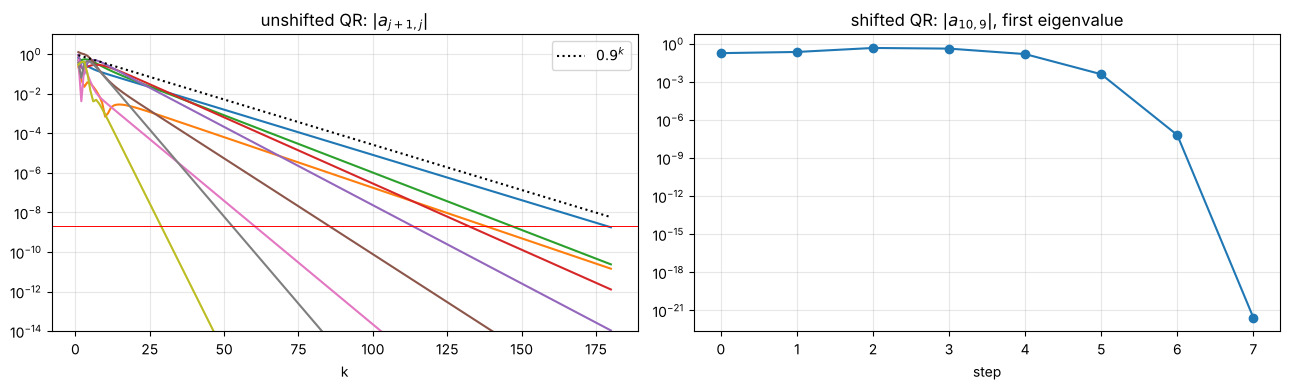

In [17]:
# --- 3. shifted QR with deflation (shift mu = a_mm, the Rayleigh quotient) ---
def qr_shifted_deflated(A, tol=1e-10, max_iter=1000, whole_row=True):
    """Shifted QR on the active leading m x m block, deflating from the bottom.
    Deflation test: the last row of the active block, off the diagonal, is below tol*||A||_F
    (whole_row=False tests only |a_{m,m-1}| as in the text of the task: fine for Hessenberg matrices)."""
    Ak = np.array(A, dtype=float)
    n = Ak.shape[0]
    stop = tol * np.linalg.norm(A, 'fro')
    eigs = np.empty(n)
    steps = 0
    traces = {}
    for m in range(n, 1, -1):
        trace = []
        while True:
            last = np.max(np.abs(Ak[m - 1, :m - 1])) if whole_row else abs(Ak[m - 1, m - 2])
            trace.append(abs(Ak[m - 1, m - 2]))
            if last < stop:
                break
            if steps >= max_iter:
                raise RuntimeError('no convergence')
            shift = Ak[m - 1, m - 1]
            Qm, Rm = np.linalg.qr(Ak[:m, :m] - shift * np.eye(m))
            Ak[:m, :m] = Rm @ Qm + shift * np.eye(m)
            steps += 1
        traces[m] = trace
        eigs[m - 1] = Ak[m - 1, m - 1]
    eigs[0] = Ak[0, 0]
    return eigs, steps, traces

eigs_s, steps_s, traces = qr_shifted_deflated(A_a)
print(f'shifted + deflated: {steps_s} QR steps in total (unshifted: {iters_unshifted});  '
      f'max eigenvalue error = {np.max(np.abs(np.sort(eigs_s) - lam_true)):.1e}')
print('QR steps spent per eigenvalue (m = 10 down to 2):', [len(traces[m]) - 1 for m in range(10, 1, -1)])
tr = np.array(traces[10])
print('\n|a_{10,9}| step by step for the first eigenvalue:')
for t, v in enumerate(tr):
    print(f'   step {t}:  {v:.3e}   (log10 = {np.log10(v):7.2f})')
lg = np.log10(tr[tr > 0])
print('ratios of consecutive log10 values:', np.round(lg[1:] / lg[:-1], 2))

# does the literal test |a_{m,m-1}| alone also work for this dense matrix?
eigs_lit, steps_lit, _ = qr_shifted_deflated(A_a, whole_row=False)
print(f'\nliteral test on |a_m,m-1| only: {steps_lit} steps, max eigenvalue error = {np.max(np.abs(np.sort(eigs_lit) - lam_true)):.1e}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
kk = np.arange(1, len(sub) + 1)
ax[0].semilogy(kk, sub); ax[0].semilogy(kk, 0.9 ** kk, 'k:', label='$0.9^k$'); ax[0].axhline(stop_a, color='r', lw=0.7)
ax[0].set_title('unshifted QR: $|a_{j+1,j}|$'); ax[0].set_xlabel('k'); ax[0].legend(); ax[0].grid(alpha=0.3); ax[0].set_ylim(1e-14, 10)
ax[1].semilogy(np.arange(len(tr)), tr, 'o-'); ax[1].set_title('shifted QR: $|a_{10,9}|$, first eigenvalue'); ax[1].set_xlabel('step'); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


**3. Shifted method with deflation** (shift $\mu=a_{mm}$, the Rayleigh quotient). It needs **29 QR steps in total** instead of 180; the steps spent per eigenvalue, from $m=10$ down to $m=2$, are $7,2,3,3,4,4,4,1,1$, and the eigenvalues are correct to $2.7\cdot10^{-15}$.

For the first eigenvalue the last subdiagonal entry goes
$0.18,\;0.23,\;0.47,\;0.42,\;0.15,\;4.0\cdot10^{-3},\;6.4\cdot10^{-8},\;2.7\cdot10^{-22}$,
i.e. $\log_{10}$ of it is $-0.74,-0.64,-0.33,-0.38,-0.81,-2.40,-7.19,-21.58$, and the ratios of consecutive exponents are $2.1,\,2.96,\,3.0,\,3.0$: after a short pre-asymptotic phase (the first four steps, while $a_{mm}$ is not yet close to an eigenvalue) the number of correct digits **triples** at every step — **cubic** convergence, not merely quadratic. This is what Rayleigh-quotient iteration does for a symmetric matrix, and the shifted QR step is exactly that iteration on the last column.

On a dense matrix the proper deflation test concerns the whole last row of the active block; testing $|a_{m,m-1}|$ alone is right for Hessenberg matrices. The code uses the whole row; the literal test gave the same result here (29 steps, same accuracy), as it should for a symmetric $A$.

In [18]:
# --- 4. a real matrix whose DOMINANT eigenvalues are a complex pair: 3 +- 2i (modulus 3.61), then 2, 1, 0.5 ---
Bc = np.zeros((5, 5))
Bc[:2, :2] = [[3.0, -2.0], [2.0, 3.0]]
Bc[2, 2], Bc[3, 3], Bc[4, 4] = 2.0, 1.0, 0.5
Qc = random_orthogonal(5)
A_cp = Qc @ Bc @ Qc.T
Ak_c, _, _, sub_c = qr_unshifted(A_cp, tol=0.0, max_iter=300)    # tol = 0: run exactly 300 steps (the test '<' never fires)
print('A_300 =\n', np.array2string(np.round(Ak_c, 4) + 0.0, precision=4))
print('\nabsolute value of the subdiagonal of A_300:', np.array2string(sub_c[-1], formatter={'float_kind': lambda v: f'{v:.1e}'}))
print('eigenvalues of the leading 2x2 block of A_300 (check only):', np.linalg.eigvals(Ak_c[:2, :2]))
print('diagonal of the rest:', np.diag(Ak_c)[2:])
print('|a_21| over the last 6 steps:', np.round(sub_c[-6:, 0], 4), '   (stays O(1): it never tends to 0)')


A_300 =
 [[ 3.   2.   0.   0.   0. ]
 [-2.   3.   0.   0.   0. ]
 [ 0.   0.   2.   0.   0. ]
 [ 0.   0.   0.   1.   0. ]
 [ 0.   0.   0.   0.   0.5]]

absolute value of the subdiagonal of A_300: [2.0e+00 9.1e-78 6.6e-92 3.9e-90]
eigenvalues of the leading 2x2 block of A_300 (check only): [3.+2.j 3.-2.j]
diagonal of the rest: [2.  1.  0.5]
|a_21| over the last 6 steps: [2. 2. 2. 2. 2. 2.]    (stays O(1): it never tends to 0)


**4. A complex pair of dominant eigenvalues** (real $5\times5$ matrix with eigenvalues $3\pm2i$ (modulus $3.61$), $2$, $1$, $0.5$, after 300 unshifted steps). $A_{300}$ is block upper triangular: the trailing diagonal is $2,\,1,\,0.5$, the other subdiagonal entries are $9\cdot10^{-78},\ 7\cdot10^{-92},\ 4\cdot10^{-90}$, but the leading $2\times2$ block remains **full**, $\begin{pmatrix}3&2\\-2&3\end{pmatrix}$, and its subdiagonal entry stays at modulus $2$ for ever; its eigenvalues are $3\pm2i$.

*Connection with §1.5, failure 1.* Power iteration on this matrix cannot converge: the iterate rotates inside the real invariant plane of the pair. The QR iteration does the same with the **first two columns together**: their span converges to the invariant plane (which is why everything below the block dies), but no real vectors inside the plane can be separated, so the pair never splits into two $1\times1$ diagonal entries. A real shift cannot separate $\lambda$ and $\bar\lambda$ either (same distance from any real number); practical codes use a complex-conjugate double shift (Francis) and accept $2\times2$ blocks on the diagonal (the real Schur form).

---
### Finding

Unshifted QR is power iteration on all columns simultaneously (nested subspaces): $A_k=Q_k^\top A\,Q_k$ stays orthogonally similar to $A$ and the entry $a_{ij}$, $i>j$, dies like $(\lambda_i/\lambda_j)^k$, so the iteration count is fixed by the *largest* ratio $\lambda_{i+1}/\lambda_i$; on $\lambda=1,\dots,10$ that is $0.9$, predicted $185$ iterations (to $10^{-10}\|A\|_F$), measured $180$. The shift $\mu=a_{mm}$ turns the last column into Rayleigh-quotient iteration: the last subdiagonal entry then drops from $4\cdot10^{-3}$ to $6\cdot10^{-8}$ to $3\cdot10^{-22}$ — the number of correct digits triples at each step — so deflating one eigenvalue costs 1–7 steps and the whole spectrum 29 steps instead of 180, with the same accuracy. And a real matrix cannot be triangularised in real arithmetic when its dominant eigenvalues are a conjugate pair: the unshifted iteration leaves a $2\times2$ block with $|a_{21}|=2$ whose eigenvalues are $3\pm2i$, which is the QR-algorithm version of the rotation seen in power iteration.

---

## ★ A2. Stable, yet it grows: non-normal iterated maps
An iterated map $\mathbf{x}_{n+1} = A\mathbf{x}_n$ with spectral radius $\rho(A) < 1$ always tends to $\mathbf{0}$. It need **not** get there monotonically. This matters whenever a linear recurrence is called "stable" because its eigenvalues are inside the unit circle — a linear RNN or an autoregressive model, for example.

1. Take $A = \begin{pmatrix} 0.95 & 10 \\ 0 & 0.9\end{pmatrix}$. Plot $\|A^n\|_2$ for $n = 0,\dots,200$ together with $\rho(A)^n$ and the bound $\kappa(P)\,\rho(A)^n$ from Lecture 3.1 ($P$ the eigenvector matrix; here you may use `np.linalg.eig`). Find the peak of $\|A^n\|_2$ and the $n$ where it happens.
2. Derive $A^n$ in closed form for this triangular $A$ and use it to explain the peak.
3. Repeat for the $20\times20$ bidiagonal matrix with $0.9$ on the diagonal and $1$ on the superdiagonal. How large does $\|A^n\|_2$ get before it decays? Why is $\kappa(P)$ useless as a bound here?

In [19]:
# Extension A2 is not attempted: at most one extension is allowed for the whole lab (A1 was chosen).